### IMPORTED REQUIRED LIBRARIES AND MODULES



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
import seaborn as sns
import joblib
import sklearn
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay,precision_recall_curve,average_precision_score
)



#### READ CSV FILE AND DATA UNDERSTANDING

In [2]:
df= pd.read_csv("ai4i2020.csv")

In [3]:
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [4]:
df = df.rename(columns={
    "Type": "type", "Air temperature [K]": "air_temp", "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque", "Tool wear [min]": "tool_wear",
    "Machine failure": "failure"})


In [5]:
df

,UDI,Product ID,type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


#### DATA UNDERSTANDING AND EDA

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   UDI           10000 non-null  int64  
 1   Product ID    10000 non-null  object 
 2   type          10000 non-null  object 
 3   air_temp      10000 non-null  float64
 4   process_temp  10000 non-null  float64
 5   rpm           10000 non-null  int64  
 6   torque        10000 non-null  float64
 7   tool_wear     10000 non-null  int64  
 8   failure       10000 non-null  int64  
 9   TWF           10000 non-null  int64  
 10  HDF           10000 non-null  int64  
 11  PWF           10000 non-null  int64  
 12  OSF           10000 non-null  int64  
 13  RNF           10000 non-null  int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 1.1+ MB


In [7]:
df.columns.tolist()

['UDI',
 'Product ID',
 'type',
 'air_temp',
 'process_temp',
 'rpm',
 'torque',
 'tool_wear',
 'failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

In [8]:
df.shape

(10000, 14)

In [9]:
df.head()


,UDI,Product ID,type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [10]:
df.tail()

,UDI,Product ID,type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [11]:
df.describe()

,UDI,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [12]:
df.isna().sum().sum()

np.int64(0)

In [13]:
df.drop(columns=["UDI", "Product ID"]).duplicated().sum()

np.int64(0)

#### CLASS IMBALANCE AND FAILURE RATE 

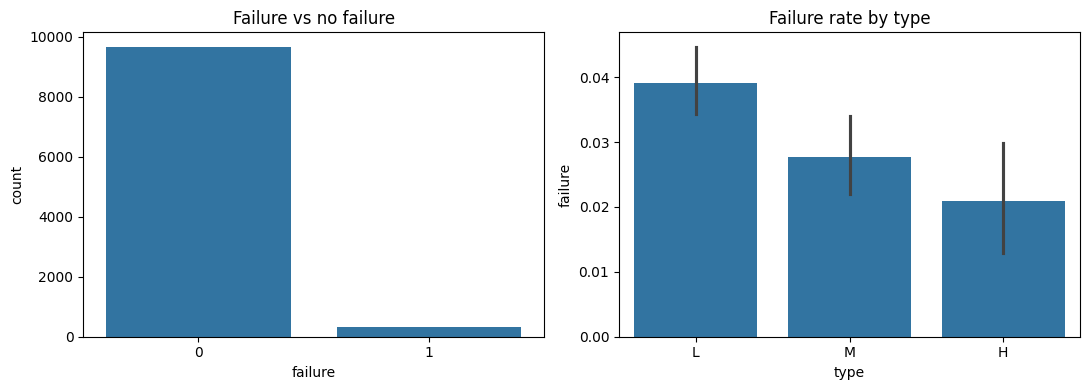

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="failure", data=df, ax=axes[0]); axes[0].set_title("Failure vs no failure")
sns.barplot(x="type", y="failure", data=df, order=["L", "M", "H"], ax=axes[1]); axes[1].set_title("Failure rate by type")
plt.tight_layout(); plt.show()

##### OUTLIERS ANALYSIS

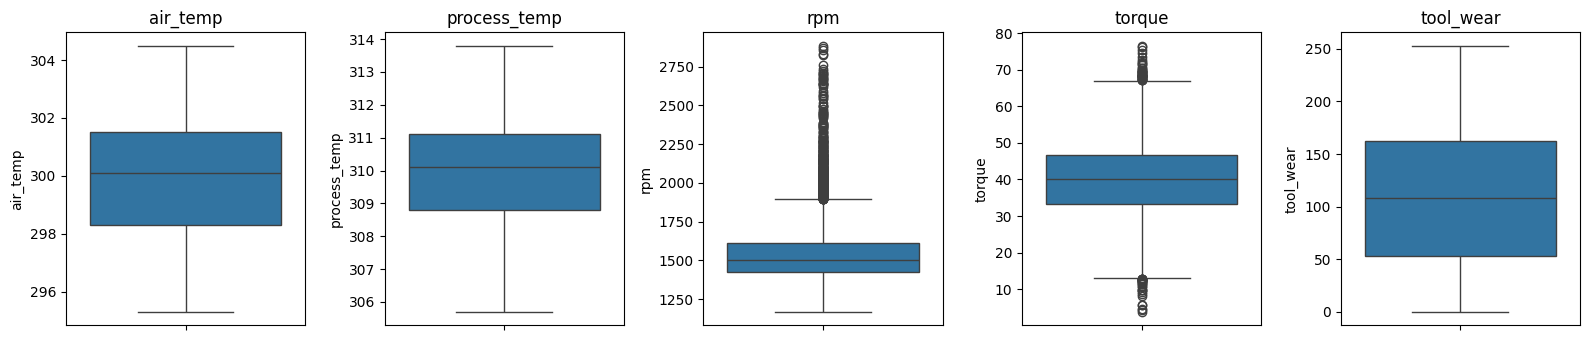

In [15]:
num_cols = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

#### DATA CLEANING AND PREPROCESSING

##### HANDLING MISSING VALUES IF ANY HERE NO NULL VALUES

In [16]:
print("Missing values before:", int(df.isna().sum().sum()))
df = df.dropna()          
print("Missing values after :", int(df.isna().sum().sum()))

Missing values before: 0
Missing values after : 0


##### REMOVAL OF DUPLICATES,LEAKAGE COLUMNS ,IDENTIFIERS ETC.

In [17]:
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
agree = ((df[modes].sum(axis=1) > 0).astype(int) == df["failure"]).mean()



In [18]:
agree

np.float64(0.9973)

In [19]:
df = df.drop(columns=["UDI", "Product ID"] + modes)
df = df.drop_duplicates()

In [20]:
df

,type,air_temp,process_temp,rpm,torque,tool_wear,failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14,0
9996,H,298.9,308.4,1632,31.8,17,0
9997,M,299.0,308.6,1645,33.4,22,0
9998,H,299.0,308.7,1408,48.5,25,0


In [21]:
df["type"].isin(["L", "M", "H"]).all()

np.True_

In [22]:
df.shape

(10000, 7)

In [23]:
print(f"Failure rate: {df['failure'].mean():.2%}  -> heavily imbalanced")

Failure rate: 3.39%  -> heavily imbalanced


#### encode of categorical values

In [24]:
df["type"] = df["type"].map({"L": 0, "M": 1, "H": 2})
df["type"].value_counts().sort_index()

type
0    6000
1    2997
2    1003
Name: count, dtype: int64

### STATISTICAL ANALYSIS

###### DESCRIPTIVE STATISTICS

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
type,10000.0,0.50030,0.671301,0.0,0.0,0.0,1.0,2.0
air_temp,10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
process_temp,10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
rpm,10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
torque,10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
tool_wear,10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0
failure,10000.0,0.03390,0.180981,0.0,0.0,0.0,0.0,1.0


##### DISTRIBUTION ANALYSIS

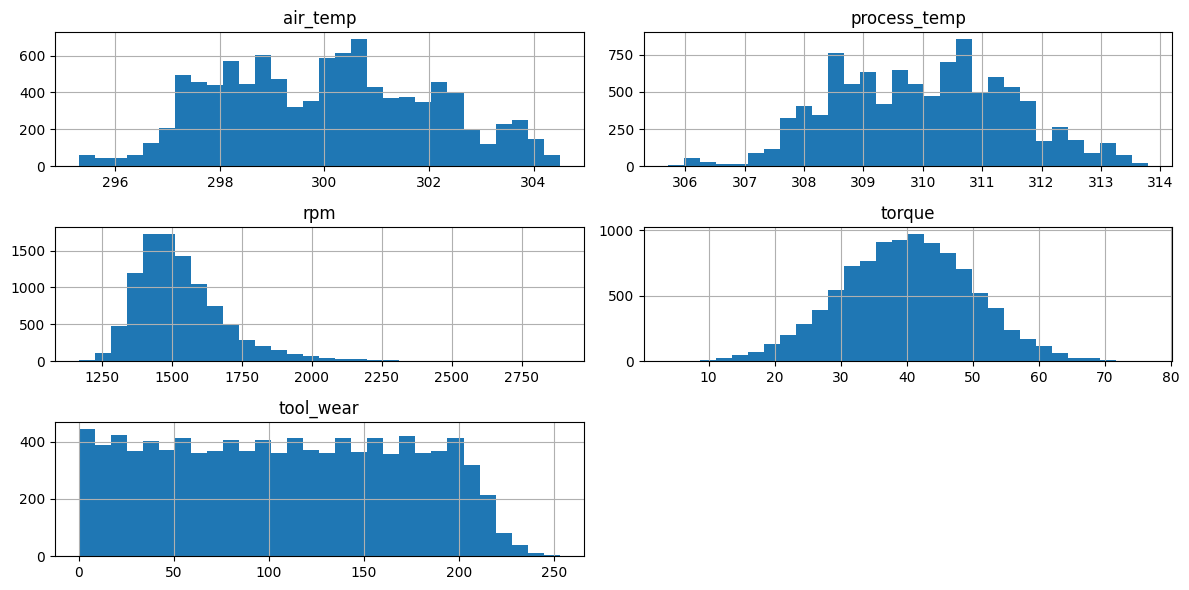

air_temp        0.11
process_temp    0.02
rpm             1.99
torque         -0.01
tool_wear       0.03


In [26]:
df[num_cols].hist(bins=30, figsize=(12, 6))
plt.tight_layout(); plt.show()


print(df[num_cols].skew().round(2).to_string())

##### CORRELATION ANALYSIS

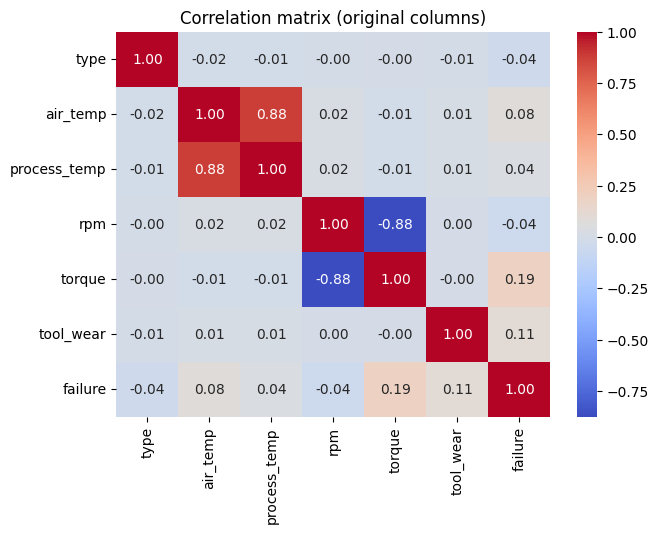

In [27]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[["type"] + num_cols + ["failure"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix (original columns)"); plt.show()

##### STATISTICAL ANAMOLY DETECTION

In [28]:
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
z_flag = (z.abs() > 3).any(axis=1)

In [29]:
z

,air_temp,process_temp,rpm,torque,tool_wear
0,-0.952342,-0.947313,0.068182,0.282186,-1.695899
1,-0.902348,-0.879915,-0.729435,0.633276,-1.648769
2,-0.952342,-1.014710,-0.227438,0.944242,-1.617349
3,-0.902348,-0.947313,-0.589992,-0.048843,-1.585930
4,-0.902348,-0.879915,-0.729435,0.001313,-1.554510
...,...,...,...,...,...
9995,-0.602387,-1.082108,0.363802,-1.051959,-1.475960
9996,-0.552394,-1.082108,0.519979,-0.821242,-1.428831
9997,-0.502400,-0.947313,0.592489,-0.660744,-1.350281
9998,-0.502400,-0.879915,-0.729435,0.853962,-1.303152


In [30]:
z_flag

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool

In [31]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
iqr_flag = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).any(axis=1)


In [32]:
iqr

air_temp          3.2
process_temp      2.3
rpm             189.0
torque           13.6
tool_wear       109.0
dtype: float64

In [33]:
iqr_flag

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool

In [34]:
stat_anomaly = pd.DataFrame({"z_score_max": z.abs().max(axis=1).round(3),
                             "z_flag": z_flag, "iqr_flag": iqr_flag})

In [35]:
stat_anomaly

,z_score_max,z_flag,iqr_flag
0,1.696,False,False
1,1.649,False,False
2,1.617,False,False
3,1.586,False,False
4,1.555,False,False
...,...,...,...
9995,1.476,False,False
9996,1.429,False,False
9997,1.350,False,False
9998,1.303,False,False


In [36]:
z_flag.sum()

np.int64(178)

In [37]:
iqr_flag.sum()

np.int64(459)

##### these are the z-score flagged and iqr flagged totals

In [38]:
print(f"Failure rate in IQR-flagged rows: {df.loc[iqr_flag, 'failure'].mean():.1%}  vs  others: {df.loc[~iqr_flag, 'failure'].mean():.1%}")

Failure rate in IQR-flagged rows: 15.7%  vs  others: 2.8%


##### anamoly score and flagged records in this 

In [39]:
flagged = df.join(stat_anomaly)
flagged[flagged["z_flag"] | flagged["iqr_flag"]].sort_values("z_score_max", ascending=False).head(10)

,type,air_temp,process_temp,rpm,torque,tool_wear,failure,z_score_max,z_flag,iqr_flag
1784,0,298.3,308.0,2886,3.8,57,1,7.514,True,True
463,0,297.4,308.7,2874,4.2,118,1,7.448,True,True
50,0,298.9,309.1,2861,4.6,143,1,7.375,True,True
847,0,296.4,307.4,2833,5.6,213,1,7.219,True,True
4296,0,301.8,310.2,2825,5.8,215,1,7.174,True,True
3369,0,301.5,310.9,2760,8.0,15,1,6.812,True,True
1391,0,298.9,310.2,2737,8.8,142,1,6.683,True,True
1095,0,296.9,307.5,2721,9.3,18,1,6.594,True,True
7997,1,301.0,312.2,2710,9.7,143,1,6.533,True,True
3867,1,302.7,311.6,2709,9.7,2,1,6.527,True,True


### FEATURE ENGINEERING AND SELECTION

#### creation of features

In [40]:
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power"] = df["torque"] * df["rpm"] * 2 * np.pi / 60
df["wear_torque"] = df["tool_wear"] * df["torque"]

In [41]:
df["temp_diff"]

0       10.5
1       10.5
2       10.4
3       10.4
4       10.5
        ... 
9995     9.6
9996     9.5
9997     9.6
9998     9.7
9999     9.7
Name: temp_diff, Length: 10000, dtype: float64

In [42]:
df["power"]


0       6951.590560
1       6826.722724
2       7749.387543
3       5927.504659
4       5897.816608
           ...     
9995    4955.129373
9996    5434.703963
9997    5753.617506
9998    7151.102638
9999    6314.601234
Name: power, Length: 10000, dtype: float64

In [43]:
df["wear_torque"]

0          0.0
1        138.9
2        247.0
3        276.5
4        360.0
         ...  
9995     413.0
9996     540.6
9997     734.8
9998    1212.5
9999    1206.0
Name: wear_torque, Length: 10000, dtype: float64

### relevant features are selected

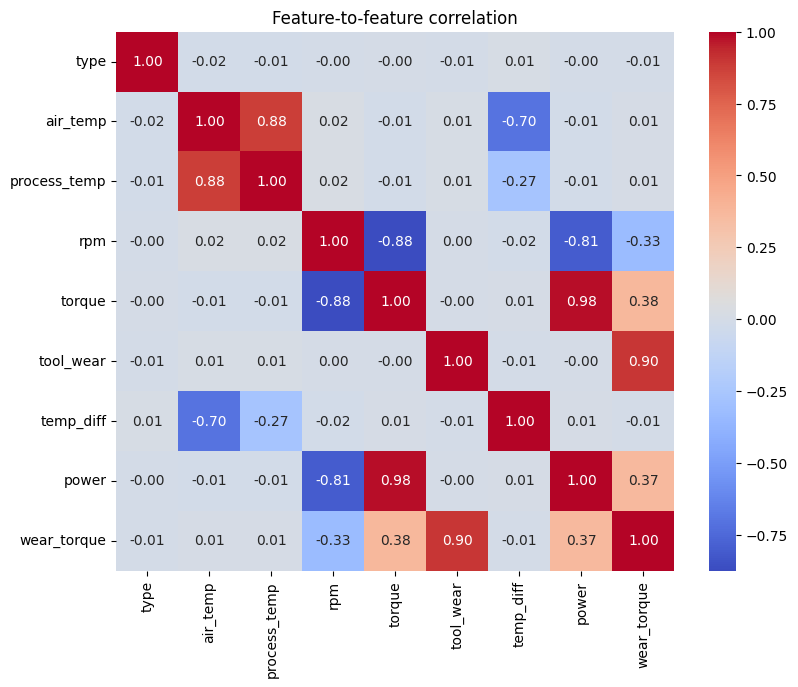

In [44]:
features = ["type"] + num_cols + ["temp_diff", "power", "wear_torque"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature-to-feature correlation"); plt.show()

### TRAIN -TEST SPLIT

In [45]:
X = df[features]
y = df["failure"]


In [46]:
X

,type,air_temp,process_temp,rpm,torque,tool_wear,temp_diff,power,wear_torque
0,1,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0
1,0,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9
2,0,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0
3,0,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5
4,0,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0
...,...,...,...,...,...,...,...,...,...
9995,1,298.8,308.4,1604,29.5,14,9.6,4955.129373,413.0
9996,2,298.9,308.4,1632,31.8,17,9.5,5434.703963,540.6
9997,1,299.0,308.6,1645,33.4,22,9.6,5753.617506,734.8
9998,2,299.0,308.7,1408,48.5,25,9.7,7151.102638,1212.5


In [47]:
y


0       0
1       0
2       0
3       0
4       0
       ..
9995    0
9996    0
9997    0
9998    0
9999    0
Name: failure, Length: 10000, dtype: int64

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


In [49]:
X_train

,type,air_temp,process_temp,rpm,torque,tool_wear,temp_diff,power,wear_torque
4058,1,302.0,310.9,1456,47.2,54,8.9,7196.676675,2548.8
1221,1,297.0,308.3,1399,46.4,132,11.3,6797.736296,6124.8
6895,1,301.0,311.6,1357,45.6,137,10.6,6479.974671,6247.2
9863,0,298.9,309.8,1411,56.3,84,10.9,8318.864043,4729.2
8711,0,297.1,308.5,1733,28.7,50,11.4,5208.456932,1435.0
...,...,...,...,...,...,...,...,...,...
980,0,296.1,306.7,1409,42.8,134,10.6,6315.145776,5735.2
4266,0,302.7,311.1,1440,39.5,146,8.4,5956.459671,5767.0
7772,2,300.3,311.5,1464,41.0,29,11.2,6285.698581,1189.0
5780,0,301.7,311.2,1517,42.4,113,9.5,6735.658425,4791.2


In [50]:
X_test


,type,air_temp,process_temp,rpm,torque,tool_wear,temp_diff,power,wear_torque
2997,0,300.5,309.8,1345,62.7,153,9.3,8831.174029,9593.1
4871,0,303.7,312.4,1513,40.1,135,8.7,6353.483679,5413.5
3858,0,302.5,311.4,1559,37.6,209,8.9,6138.504494,7858.4
951,2,295.6,306.3,1509,35.8,60,10.7,5657.191555,2148.0
6463,2,300.5,310.0,1358,60.4,102,9.5,8589.449418,6160.8
...,...,...,...,...,...,...,...,...,...
1686,2,297.9,307.3,1663,28.7,7,9.4,4998.074944,200.9
6952,0,300.8,311.3,1498,40.2,73,10.5,6306.181765,2934.6
9954,1,298.1,307.9,1446,42.8,121,9.8,6480.979981,5178.8
5728,1,302.4,311.9,1422,46.4,194,9.5,6909.493219,9001.6


In [51]:
y_train

4058    0
1221    0
6895    0
9863    0
8711    0
       ..
980     0
4266    0
7772    0
5780    0
1424    0
Name: failure, Length: 8000, dtype: int64

In [52]:
y_test

2997    0
4871    0
3858    0
951     0
6463    0
       ..
1686    0
6952    0
9954    0
5728    0
9191    0
Name: failure, Length: 2000, dtype: int64

In [53]:
 X_train.shape

(8000, 9)

In [54]:
y_train.sum()

np.int64(271)

In [55]:
X_test.shape

(2000, 9)

In [56]:
y_test.sum()

np.int64(68)

In [57]:
print("Leakage checks passed in features")

Leakage checks passed in features


### TRAIN MACHINE LEARNING MODELS

#### ANAMOLY MODEL

##### ISOLATION FOREST

In [58]:
anomaly_model = make_pipeline(
    StandardScaler(),
    IsolationForest(n_estimators=200, contamination=0.05, random_state=42))
anomaly_model.fit(X_train[num_cols])

,steps,"[('standardscaler', ...), ('isolationforest', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_estimators,200
,max_samples,'auto'
,contamination,0.05
,max_features,1.0


In [59]:
raw_train = -anomaly_model.score_samples(X_train[num_cols])
score_min, score_max = float(raw_train.min()), float(raw_train.max())


In [60]:
raw_train

array([0.43551951, 0.46163819, 0.4369998 , ..., 0.44616648, 0.42220743,
       0.4628018 ], shape=(8000,))

In [61]:
score_min, score_max 


(0.39907528456778324, 0.7147094322369184)

In [62]:
raw_test = -anomaly_model.score_samples(X_test[num_cols])
anom_test = np.clip((raw_test - score_min) / (score_max - score_min), 0, 1)


In [63]:
raw_test 


array([0.49675105, 0.47883215, 0.46709704, ..., 0.43763123, 0.4611541 ,
       0.54453087], shape=(2000,))

In [64]:
anom_test

array([0.3094588 , 0.2526877 , 0.21550824, ..., 0.12215391, 0.19667965,
       0.46083601], shape=(2000,))

In [65]:
flag_test = anomaly_model.predict(X_test[num_cols]) == -1

In [66]:
flag_test


array([False, False, False, ..., False, False, False], shape=(2000,))

In [67]:
print("Test rows flagged anomalous:", int(flag_test.sum()), "of", len(X_test))
print(f"Failure rate in flagged rows    : {y_test[flag_test].mean():.1%}")
print(f"Failure rate in not-flagged rows: {y_test[~flag_test].mean():.1%}")

Test rows flagged anomalous: 101 of 2000
Failure rate in flagged rows    : 8.9%
Failure rate in not-flagged rows: 3.1%


#### COMPARE CLASSIFICATION MODEL WITH K-FOLD CROSS VALIDATION

###### used by XGBoost to handle imbalance 

In [68]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

In [69]:
ratio

np.float64(28.52029520295203)

In [70]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=ratio, eval_metric="logloss", random_state=42),
    "SVM": make_pipeline(StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42)),
}


In [71]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc",
           "f1": "f1", "recall": "recall", "precision": "precision"}


In [72]:
cv_rows = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {"cv_" + m: scores["test_" + m].mean() for m in scoring}

cv_results = pd.DataFrame(cv_rows).T.round(3).sort_values("cv_pr_auc", ascending=False)
cv_results

,cv_pr_auc,cv_roc_auc,cv_f1,cv_recall,cv_precision
Random Forest,0.893,0.975,0.863,0.797,0.942
XGBoost,0.869,0.979,0.792,0.841,0.750
SVM,0.688,0.960,0.461,0.874,0.314
Logistic Regression,0.458,0.923,0.272,0.845,0.162


##### selecton of best models

In [73]:
best_name = cv_results["cv_pr_auc"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)

Best model: Random Forest


### FAILURE CLASSIFICTION

In [74]:
f_prob = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, f_prob)
prec, rec = prec[:-1], rec[:-1]
f2 = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)     
threshold = float(thr[np.argmax(f2)])
print(f"Chosen threshold: {threshold:.3f}  (default = 0.5)")

Chosen threshold: 0.409  (default = 0.5)


#### fitting the best model and predict the probability of failure 

In [75]:
best_model.fit(X_train, y_train)
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

In [76]:
 int(test_pred.sum())

60

In [77]:
len(test_pred)

2000

In [78]:
print("Predicted failures in test set is", 60 ,"of" ,2000)

Predicted failures in test set is 60 of 2000


#### MODEL EVALUATION 

##### test-set metrics

In [79]:
test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "roc_auc": roc_auc_score(y_test, test_prob),
    "pr_auc": average_precision_score(y_test, test_prob)}


In [80]:
test_metrics

{'accuracy': 0.992,
 'precision': 0.9333333333333333,
 'recall': 0.8235294117647058,
 'f1': 0.875,
 'roc_auc': 0.970207648276702,
 'pr_auc': 0.8708607332323017}

In [81]:
print(pd.Series(test_metrics).round(3).to_string())

accuracy     0.992
precision    0.933
recall       0.824
f1           0.875
roc_auc      0.970
pr_auc       0.871


In [82]:
print(classification_report(y_test, test_pred, target_names=["No failure", "Failure"]))

              precision    recall  f1-score   support

  No failure       0.99      1.00      1.00      1932
     Failure       0.93      0.82      0.88        68

    accuracy                           0.99      2000
   macro avg       0.96      0.91      0.94      2000
weighted avg       0.99      0.99      0.99      2000



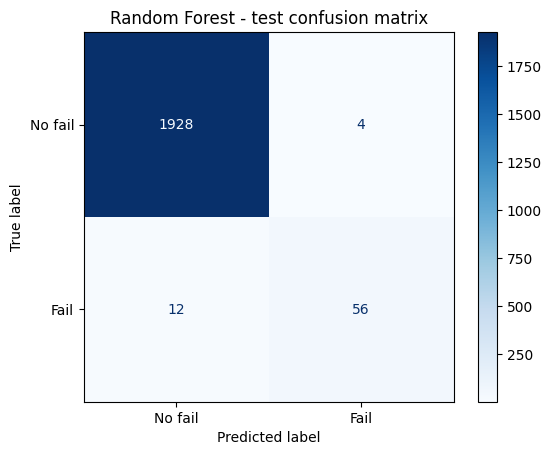

In [83]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["No fail", "Fail"], cmap="Blues")
plt.title(f"{best_name} - test confusion matrix"); plt.show()

##### Permutation in test data

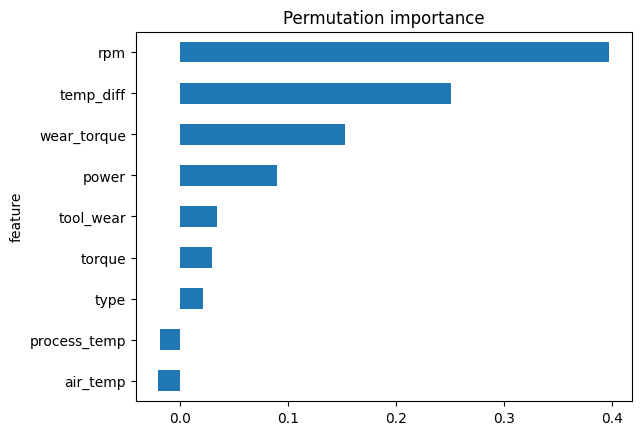

In [84]:
perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=42)
importance = pd.DataFrame({"feature": features, "importance": perm.importances_mean}).sort_values("importance")
importance.plot(x="feature", y="importance", kind="barh", legend=False, title="Permutation importance")
plt.show()

#### combine of anamaly results and failure risk

In [85]:
W_FAIL, W_ANOM = 0.70, 0.30
LOW_T, HIGH_T = 0.30, 0.60

risk = W_FAIL * test_prob + W_ANOM * anom_test

out = X_test.copy()
out["actual_failure"] = y_test
out["failure_prob"] = test_prob.round(4)
out["anomaly_score"] = anom_test.round(4)
out["risk_score"] = risk.round(4)
out[["failure_prob", "anomaly_score", "risk_score"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
failure_prob,2000.0,0.037,0.145,0.000,0.000,0.000,0.006,0.989
anomaly_score,2000.0,0.225,0.156,0.001,0.106,0.187,0.304,0.842
risk_score,2000.0,0.093,0.122,0.000,0.033,0.059,0.105,0.919


#### MACHINE FAILURE RISK CLASSIFICATION

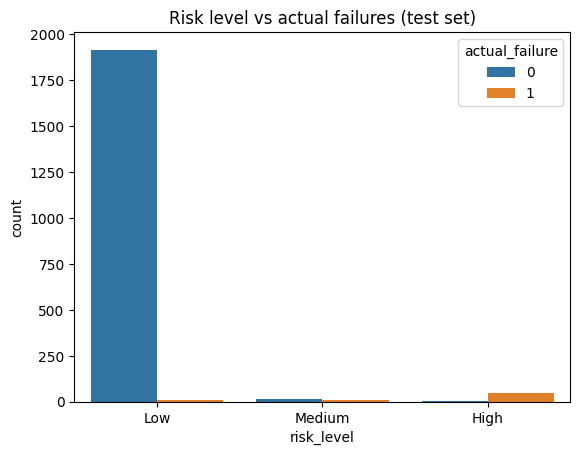

In [86]:
out["risk_level"] = np.where(risk >= HIGH_T, "High", np.where(risk >= LOW_T, "Medium", "Low"))

sns.countplot(x="risk_level", hue="actual_failure", data=out, order=["Low", "Medium", "High"])
plt.title("Risk level vs actual failures (test set)"); plt.show()



In [87]:
risk_table = (out.groupby("risk_level")["actual_failure"]
                 .agg(machines="count", failures="sum", failure_rate="mean")
                 .reindex(["Low", "Medium", "High"]).round(3))


In [88]:
risk_table

,machines,failures,failure_rate
risk_level,,,
Low,1926,10,0.005
Medium,25,11,0.440
High,49,47,0.959


#### MAINTENANCE DECISION SUPPORT SYSTEM

In [89]:
out["recommended_action"] = out["risk_level"].map({
    "Low": "Normal - no immediate action",
    "Medium": "Schedule inspection / monitor",
    "High": "Immediate maintenance required"})


In [90]:
out["recommended_action"]

2997    Normal - no immediate action
4871    Normal - no immediate action
3858    Normal - no immediate action
951     Normal - no immediate action
6463    Normal - no immediate action
                    ...             
1686    Normal - no immediate action
6952    Normal - no immediate action
9954    Normal - no immediate action
5728    Normal - no immediate action
9191    Normal - no immediate action
Name: recommended_action, Length: 2000, dtype: object

In [91]:
out.sort_values("risk_score", ascending=False)[["type", "rpm", "torque", "tool_wear", "risk_score", "risk_level", "recommended_action"]].head(10)

,type,rpm,torque,tool_wear,risk_score,risk_level,recommended_action
7997,1,2710,9.7,143,0.9192,High,Immediate maintenance required
7011,0,2633,12.2,17,0.9111,High,Immediate maintenance required
380,0,2564,12.8,127,0.9050,High,Immediate maintenance required
1391,0,2737,8.8,142,0.9012,High,Immediate maintenance required
4296,0,2825,5.8,215,0.8342,High,Immediate maintenance required
2444,0,1267,68.2,76,0.8295,High,Immediate maintenance required
4342,1,1284,68.2,111,0.8247,High,Immediate maintenance required
6497,0,1312,65.3,192,0.7991,High,Immediate maintenance required
3935,1,1227,68.2,187,0.7949,High,Immediate maintenance required
4565,2,1275,55.0,25,0.7881,High,Immediate maintenance required


In [92]:
print(f"Best model USING  CV PR-AUC): {best_name}")

Best model USING  CV PR-AUC): Random Forest


In [93]:
print("Test-set performance:")
print(pd.Series(test_metrics).round(3).to_string())
print()

Test-set performance:
accuracy     0.992
precision    0.933
recall       0.824
f1           0.875
roc_auc      0.970
pr_auc       0.871



In [94]:
print("Risk levels vs actual failures (test set):")
print(risk_table.to_string())

Risk levels vs actual failures (test set):
            machines  failures  failure_rate
risk_level                                  
Low             1926        10         0.005
Medium            25        11         0.440
High              49        47         0.959


In [95]:
config = {"features": features, "num_cols": num_cols, "best_name": best_name,
          "threshold": threshold, "score_min": score_min, "score_max": score_max,
          "w_fail": W_FAIL, "w_anom": W_ANOM, "low_t": LOW_T, "high_t": HIGH_T,
          "test_metrics": test_metrics, "sklearn_version": sklearn.__version__}


In [100]:

joblib.dump(best_model, ARTIFACT_DIR / "failure_model.pkl")
joblib.dump(anomaly_model, ARTIFACT_DIR / "anomaly_model.pkl")
joblib.dump(config, ARTIFACT_DIR / "config.pkl")


['artifacts\\config.pkl']

In [101]:
cv_results.to_csv(ARTIFACT_DIR / "cv_results.csv")
out.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)
importance.to_csv(ARTIFACT_DIR / "feature_importance.csv", index=False)


In [103]:
from pathlib import Path

DATA_PATH = "ai4i2020.csv"

In [104]:
ARTIFACT_DIR = Path(r"C:\Users\ASHWIN VINOD\Desktop\machine_failure_ml_project\Statiscal_Anamoly_Detection_and_machine-_failure_prediction\artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)